# 02 · Logistic regression

Normal residuals and constant variance are not expected for a binary outcome, so `check_model()` runs a different set of checks: collinearity, influence, binned residuals and the uniformity of simulated residuals.

In [1]:
import warnings

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore", category=FutureWarning)
DATA = "../tests/data"
mtcars = pd.read_csv(f"{DATA}/mtcars.csv", index_col=0)
logit = smf.glm("vs ~ mpg + wt", data=mtcars, family=sm.families.Binomial()).fit()
logit.params

Intercept   -12.541222
mpg           0.524064
wt            0.582860
dtype: float64

In [2]:
from checkmodel import check_model

report = check_model(logit)
report

# Model checks: GLM (binomial, logit link), n = 32

Posterior predictive check: OK: Model-predicted data resemble the observed data (proportion of 1s p = 0.600).
Collinearity: OK: Low collinearity (all VIF < 5; max 2.63).
Influential observations: OK: No outliers detected (Cook's distance > 0.709).
Binned residuals: Warning: Probably bad model fit. Only about 50% of the residuals are inside the error bounds.
Uniformity of residuals: OK: Simulated residuals appear as uniformly distributed (p = 0.986).

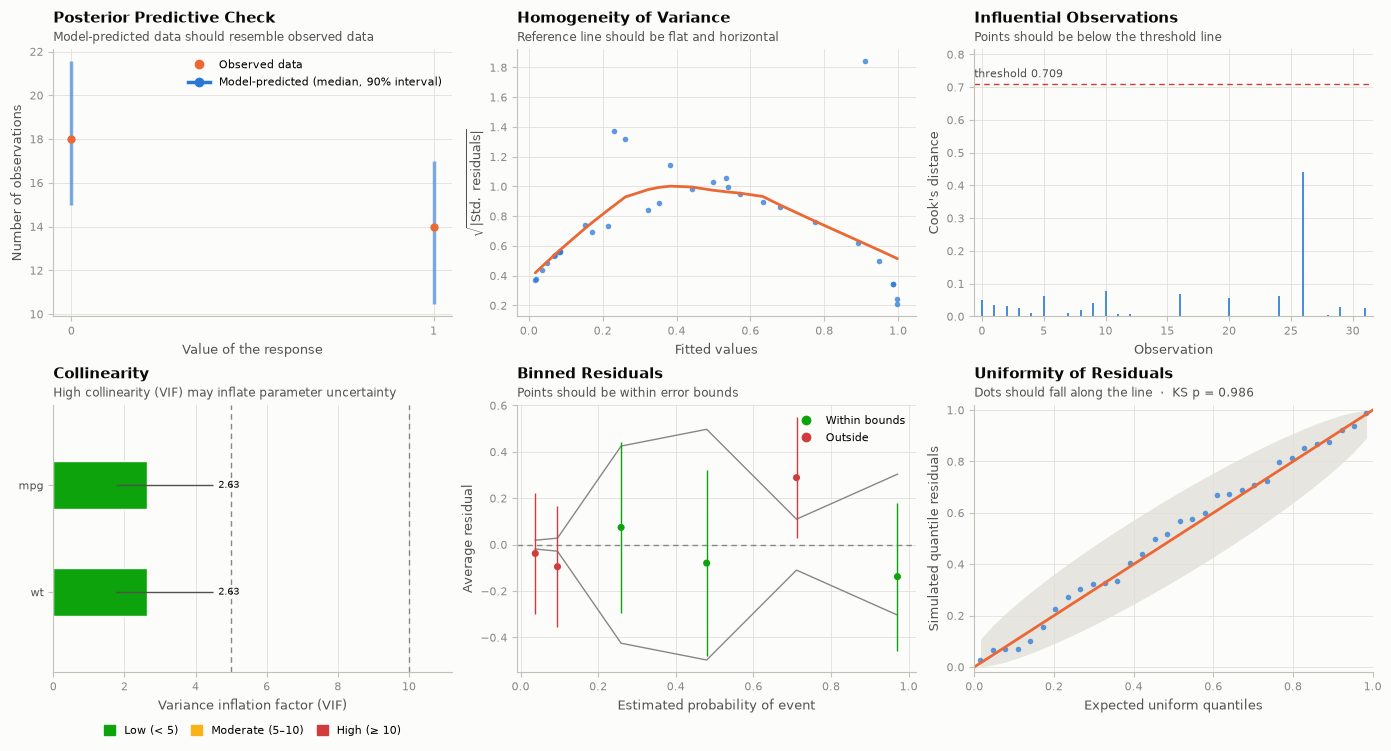

In [3]:
report.plot();

## Binned residuals

The observations are grouped by predicted probability; in a well-specified model about 95% of the binned mean residuals fall inside the error bounds.

In [4]:
from checkmodel import binned_residuals

binned = binned_residuals(logit)
binned.to_dataframe().round(3)

,xbar,ybar,n,x_lo,x_hi,se,CI_low,CI_high,inside
0,0.038,-0.038,5,0.017,0.069,0.019,-0.299,0.223,False
1,0.095,-0.095,5,0.071,0.152,0.028,-0.356,0.166,False
2,0.259,0.074,6,0.172,0.354,0.425,-0.293,0.441,True
3,0.480,-0.080,5,0.384,0.541,0.497,-0.480,0.321,True
4,0.711,0.289,5,0.573,0.891,0.110,0.028,0.550,False
5,0.971,-0.138,6,0.911,0.998,0.304,-0.456,0.181,True


Only half of the bins fall inside their bounds here. With 32 cars there are just six bins of five or six cars each, so treat this as a prompt to look at the plot rather than a firm verdict; on larger data the check is far more informative.

## Simulated residuals

Raw residuals of a binary outcome are not expected to look normal. Simulated quantile residuals (DHARMa's approach, `simulate_residuals()`) are uniform for any family when the model is right, so `check_residuals()` tests them against the uniform distribution. The same simulations can be reused by `check_overdispersion()`.

In [5]:
from checkmodel import check_overdispersion, check_residuals, simulate_residuals

sim = simulate_residuals(logit, random_state=0)
print(check_residuals(sim))
print(check_overdispersion(sim))
sim.plot();

OK: Simulated residuals appear as uniformly distributed (p = 0.986).
OK: No overdispersion detected (dispersion ratio = 1.058, p = 0.712).


## Pseudo-R²

`r2()` picks Tjur's R² for a binary outcome, as R's `performance` does; the other measures are available too.

In [6]:
from checkmodel import r2, r2_coxsnell, r2_mcfadden, r2_nagelkerke

r2(logit)

# R2 for Logistic Regression
  Tjur's R2: 0.478

In [7]:
{"Cox & Snell": r2_coxsnell(logit), "Nagelkerke": r2_nagelkerke(logit), "McFadden": r2_mcfadden(logit)["R2"]}

{'Cox & Snell': 0.44014071515583786,
 'Nagelkerke': 0.5899593018371635,
 'McFadden': 0.42321448886751833}

## The same model in scikit-learn

scikit-learn models need the training data. With `C=np.inf` (no penalty) the numbers match the statsmodels fit.

In [8]:
import numpy as np
from sklearn.linear_model import LogisticRegression

X, y = mtcars[["mpg", "wt"]], mtcars["vs"]
sk = LogisticRegression(C=np.inf, max_iter=10_000).fit(X, y)
r2(sk, X, y)

# R2 for Logistic Regression
  Tjur's R2: 0.478